Files already downloaded and verified
Files already downloaded and verified

Epoch  0 ----- [Accuracy:   9.75%]
Epoch  1 ----- [Accuracy:  37.49%]
Epoch  2 ----- [Accuracy:  43.28%]
Epoch  3 ----- [Accuracy:  46.66%]
Epoch  4 ----- [Accuracy:  43.34%]
Epoch  5 ----- [Accuracy:  49.18%]
Epoch  6 ----- [Accuracy:  60.80%]
Epoch  7 ----- [Accuracy:  48.36%]
Epoch  8 ----- [Accuracy:  55.74%]
Epoch  9 ----- [Accuracy:  59.39%]
Epoch 10 ----- [Accuracy:  56.35%]


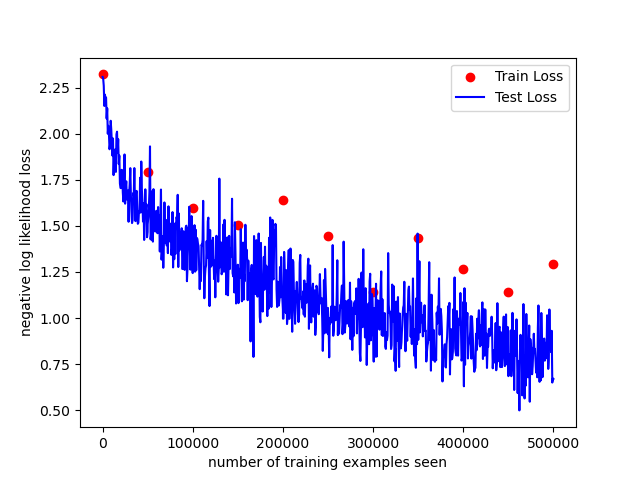

In [12]:
# [Imports] ############################################################################################################
import os
import sys
import time
import datetime
import copy

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import LightSource
import scipy


# [Parameter and Convenience] ##########################################################################################
n_epochs         = 10
batch_size_train = 64
batch_size_test  = 100
learning_rate    = 0.01
momentum         = 0.5
log_interval     = 10


# [Function Definitions] ###############################################################################################
def do_epoch_loss(network, testloader, loss_function):
    test_loss = 0
    # calculate the loss over the whole validation set and store it
    for batchdata, label in testloader:
        prediction = network(batchdata)
        test_loss += loss_function(prediction, label, reduction="sum") # sum up all losses for all samples
    test_loss = test_loss / len(testloader.dataset) # normalize by "nr of samples"
    
    return test_loss

def do_epoch_accuracy(network, testloader):
    test_correct = 0
    for batchdata, label in testloader:
        prediction = network(batchdata)
        label_prediction = prediction.data.max(1, keepdim=True)[1] # getting the actual most likely labels
        test_correct += label_prediction.eq(label.data.view_as(label_prediction)).sum() # get nr of correct labels
    test_correct = 100. * test_correct / len(testloader.dataset)
    
    # returns the percentage of correct labels
    return test_correct

def plot_info_graph(train_losses, test_losses, train_counter, test_counter):
    
    fig = plt.figure()
    plt.scatter(test_counter, test_losses, color='red')
    plt.plot(train_counter, train_losses, color='blue')
    plt.legend(['Train Loss', 'Test Loss'], loc='upper right')
    plt.xlabel('number of training examples seen')
    plt.ylabel('negative log likelihood loss')    
    
    return

# [Class Definitions] ##################################################################################################
class my_cifar_net(nn.Module):
    def __init__(self):
        super().__init__()
        
        # define layers 
        self.convA = nn.Conv2d(  3,  32, kernel_size=5, stride=2, padding=2)
        self.convB = nn.Conv2d( 32,  64, kernel_size=3, stride=1, padding=1)
        self.convC = nn.Conv2d( 64,  64, kernel_size=3, stride=1, padding=1)
        self.convD= nn.Conv2d( 64, 128, kernel_size=5, stride=2, padding=2)
        self.convE = nn.Conv2d(128, 128, kernel_size=5, stride=2, padding=2) 
        self.batchnorm32  = nn.BatchNorm2d( 32)
        self.batchnorm64  = nn.BatchNorm2d( 64)
        self.batchnorm128 = nn.BatchNorm2d(128)
        
        self.fc1 = nn.Linear(2048, 100)
        self.fc2 = nn.Linear( 100,  50)
        self.fc3 = nn.Linear(  50,  10)
        self.batchnorm100 = nn.BatchNorm1d(100)
        
        
        self.activation = F.relu
        
        self.drop_conv = nn.Dropout2d(p=0.3)
        self.drop_fc   = nn.Dropout(p=0.5)
    
    def forward(self, x):
        # INPUT: Batch x 3x32x32 images
        x = self.convA(x)                          
        x = self.batchnorm32(x)
        x = self.activation(x)
        # out 32 x 16x16
        x = self.convB(x)
        x = self.batchnorm64(x)
        x = self.activation(x)
        x = self.drop_conv(x)
        # out 64 x 16x16
        x = self.convC(x)
        x = self.batchnorm64(x)
        x = self.activation(x)
        x = self.drop_conv(x)
        # out 64 x 16x16  
        x = self.convD(x)
        x = self.batchnorm128(x)
        x = self.activation(x)
        # out 128 x 8x8
        x = self.convE(x)
        x = self.batchnorm128(x)
        x = self.activation(x)
        # out 128 x 4x4
        x = x.view(-1, 2048)
        # out 1, 2048
        x = self.fc1(x)
        x = self.batchnorm100(x)
        x = self.activation(x)
        x = self.drop_fc(x)
        x = self.fc2(x)
        x = self.activation(x)
        x = self.fc3(x)

        x = F.log_softmax(x, dim=1)
    
        return x



# [Do Work] ############################################################################################################
# import Datasets: each element is a Tuple of img (32x32) and label(0-9)
cifar_trainset = datasets.CIFAR10(root='./data', train=True,  download=True, transform=transforms.ToTensor()) # 50'000
cifar_testset  = datasets.CIFAR10(root='./data', train=False, download=True, transform=transforms.ToTensor()) # 10'000
# Load the Datasets into DataLoader Objects
cifar_trainloader = data.DataLoader(cifar_trainset, batch_size=batch_size_train, shuffle=True)
cifar_testloader  = data.DataLoader(cifar_testset,  batch_size=batch_size_test,  shuffle=False)

# build network --------------------------------------------------------------------------------------------------------
net1          = my_cifar_net()
optimizer     = optim.SGD(net1.parameters(), lr=learning_rate, momentum=momentum)
loss_function = F.nll_loss

train_losses  = [] # track [training losses (Batch iteration)]
test_losses   = [] # track [all validation losses (Epoch iteration)]
train_counter = [] # track [number of training samples seen (for plot x-axis)]
test_counter  = [] # track [number of training samples seen @ validation (for plot x-axis)]
test_counter  = [i*len(cifar_trainloader.dataset) for i in range(n_epochs + 1)] # includes a 0 for the first eval run

# initial network evaluation -------------------------------------------------------------------------------------------
with torch.no_grad():
    test_losses.append(do_epoch_loss(net1, cifar_testloader, loss_function))
    print(f"\nEpoch {0:>2} ----- [Accuracy: {do_epoch_accuracy(net1, cifar_testloader):>6.2f}%]")

# main loop iterate over EPOCHS ------------------------------------------------------
for E in range(1, n_epochs+1):
    net1.train()
    
    # loop through one whole BATCH ---------------------------------------------------
    for batch_idx, (batchdata, label) in enumerate(cifar_trainloader):
        prediction = net1(batchdata)
        loss       = loss_function(prediction, label) 
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        # logging every log_interval steps
        if batch_idx % log_interval == 0:
            # console output
            percent = 100. * (batch_idx+1) / len(cifar_trainloader)
            print(f"Epoch {E:>2}       (progress: {percent:>6.2f}%)", end="\r")
            # saving training loss to list
            train_losses.append(loss.item()) #.item(): just the value of loss (alt. no_grad, but can't be used here?)
            train_counter.append(((batch_idx+1)*batch_size_train) + ((E-1)*len(cifar_trainloader.dataset)))
    
    # do evaluation after one full epoch ---------------------------------------------
    net1.eval()
    with torch.no_grad():
        test_losses.append(do_epoch_loss(net1, cifar_testloader, loss_function))
        print(f"Epoch {E:>2} ----- [Accuracy: {do_epoch_accuracy(net1, cifar_testloader):>6.2f}%]")
        
plot_info_graph(train_losses, test_losses, train_counter, test_counter)

In [13]:
# analyze network and get PARAM LIST
for name, param in net1.named_parameters():
    if param.requires_grad:
        print(f"Name:  {name:<14} {param.data.size()}")

# Save network Parameters. get parameters (all of them)
params_optimal = []
for el in net1.parameters():
    params_optimal.append(el.data) # this (.data) acutally only takes the tensor and discards the object or whatever
    # print(el.size())

# backup parameters
params_optimal_BACKUP = copy.deepcopy(params_optimal)

Name:  convA.weight   torch.Size([32, 3, 5, 5])
Name:  convA.bias     torch.Size([32])
Name:  convB.weight   torch.Size([64, 32, 3, 3])
Name:  convB.bias     torch.Size([64])
Name:  convC.weight   torch.Size([64, 64, 3, 3])
Name:  convC.bias     torch.Size([64])
Name:  convD.weight   torch.Size([128, 64, 5, 5])
Name:  convD.bias     torch.Size([128])
Name:  convE.weight   torch.Size([128, 128, 5, 5])
Name:  convE.bias     torch.Size([128])
Name:  batchnorm32.weight torch.Size([32])
Name:  batchnorm32.bias torch.Size([32])
Name:  batchnorm64.weight torch.Size([64])
Name:  batchnorm64.bias torch.Size([64])
Name:  batchnorm128.weight torch.Size([128])
Name:  batchnorm128.bias torch.Size([128])
Name:  fc1.weight     torch.Size([100, 2048])
Name:  fc1.bias       torch.Size([100])
Name:  fc2.weight     torch.Size([50, 100])
Name:  fc2.bias       torch.Size([50])
Name:  fc3.weight     torch.Size([10, 50])
Name:  fc3.bias       torch.Size([10])
Name:  batchnorm100.weight torch.Size([100])
Name

In [16]:
# Param definition -----------------------------------------------------------------------------------------------------
num_batches_for_loss_calc = 5 # batch size 100, 100*100 = 10'000 is max

S       = 0.8  # scale stepsize for grid by S
k_range = 50 
j_range = 50
nr_calcs = k_range * j_range

# Disables all Dropouts etc... should be very smooth
do_evalmode  = True   
# the real WITH dropout, etc
do_trainmode = True 

# Function Definition --------------------------------------------------------------------------------------------------
def calc_eval_loss_evalmode(net, loss_function, test_loader, batch_lim):
    net.eval()
    loss = 0
    if batch_lim == 0:
        return loss
    with torch.no_grad():
        for batch_idx, (data_batch, label) in enumerate(test_loader):
            prediction = net(data_batch)
            loss += loss_function(prediction, label, reduction="sum")
            if (batch_idx+1) >= batch_lim:
                break   
        loss = loss / (batch_size_test*(batch_idx+1))
    
    return loss

def calc_eval_loss_trainmode(net, loss_function, test_loader, batch_lim):
    net.train()
    loss = 0
    if batch_lim == 0:
        return loss
    
    for batch_idx, (data_batch, label) in enumerate(test_loader):
        prediction = net(data_batch)
        loss += loss_function(prediction, label, reduction="sum")
        if (batch_idx+1) >= batch_lim:
            break   
    loss = loss / (batch_size_test*(batch_idx+1))
    
    return loss

def print_progress(counter, nr_calcs):
    character = "#"
    perc = 100*counter/nr_calcs # percent progress
    print(f"Creating Loss map:      calculation progress [{counter}/{nr_calcs}] ", end="")
    print(f"[{perc:.0f}%] [{character*round(0.5*perc):-<50}]", end="\r")  #  [{"#"*round(0.1*perc):<10}]
    return

# generate the Random Direction(s) in parameter space of model ---------------------------------------------------------
random_dir_1 = []
random_dir_2 = []
square_sum_1 = 0
square_sum_2 = 0
for i, el in enumerate(params_optimal):
    size = el.size()
    randomtensor_1 = torch.rand(size) - 0.5*torch.ones(size) # random direction, positive and negative rand is € [0, 1)
    randomtensor_2 = torch.rand(size) - 0.5*torch.ones(size)
    random_dir_1.append(randomtensor_1)
    random_dir_2.append(randomtensor_2)
    square_sum_1 += torch.sum(torch.square(randomtensor_1))
    square_sum_2 += torch.sum(torch.square(randomtensor_2))
# normalize the whole "direction" vector and Scale it with the factor S  
for i, el in enumerate(random_dir_1):
    random_dir_1[i] /= np.sqrt(square_sum_1)
    random_dir_2[i] /= np.sqrt(square_sum_2)
    random_dir_1[i] *= S
    random_dir_2[i] *= S
   
# iterate through all datapoints ---------------------------------------------------------------------------------------
loss_mtx_trainmode = np.zeros((k_range, j_range))
loss_mtx_evalmode  = np.zeros((k_range, j_range))

# do loss calculation for EVALMODE ---------
if do_evalmode:
    counter = 0
    for j in range(j_range):
        for k in range(k_range):
            # incrementally update net parameters
            for i, param in enumerate(net1.parameters()):
                k_offset = (k_range-1)/2*random_dir_1[i]
                j_offset = (j_range-1)/2*random_dir_2[i]
                param.data = params_optimal[i] - k_offset - j_offset + k*random_dir_1[i] + j*random_dir_2[i] 
            # claculate loss @ k, j in parameter space slice
            loss = calc_eval_loss_evalmode(net1, loss_function, cifar_testloader, num_batches_for_loss_calc)
            loss_mtx_evalmode[k, j] = loss
            counter += 1
            print_progress(counter, nr_calcs)

print() 

# do loss calculation for TRAINMODE -------
if do_trainmode:
    counter = 0
    for j in range(j_range):
        for k in range(k_range):
            # incrementally update net parameters
            for i, param in enumerate(net1.parameters()):
                k_offset = (k_range-1)/2*random_dir_1[i]
                j_offset = (j_range-1)/2*random_dir_2[i]
                param.data = params_optimal[i] - k_offset - j_offset + k*random_dir_1[i] + j*random_dir_2[i] 
            # claculate loss @ k, j in parameter space slice
            loss = calc_eval_loss_trainmode(net1, loss_function, cifar_testloader, num_batches_for_loss_calc)
            loss_mtx_trainmode[k, j] = loss
            counter += 1
            print_progress(counter, nr_calcs)

Creating Loss map:      calculation progress [2500/2500] [100%] [##################################################]


C:\Users\elias\AppData\Local\Temp\ipykernel_5720\2841840131.py:8: RuntimeWarning: divide by zero encountered in log
  surf = ax[0].plot_surface(X, Y, np.log(loss_mtx_trainmode), cmap=cm.coolwarm, linewidth=0, antialiased=False)


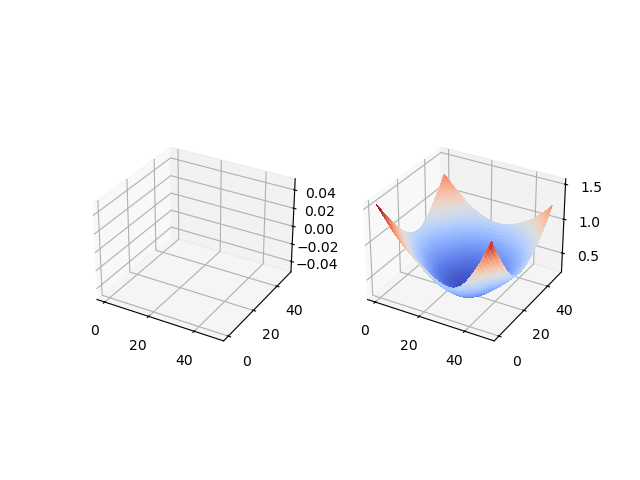

In [15]:
%matplotlib widget

X = np.linspace(0, k_range -1, k_range)
Y = np.linspace(0, j_range -1, j_range)
X, Y = np.meshgrid(X, Y)

fig, ax = plt.subplots(1, 2, subplot_kw={"projection": "3d"})
surf = ax[0].plot_surface(X, Y, np.log(loss_mtx_trainmode), cmap=cm.coolwarm, linewidth=0, antialiased=False)
surf = ax[1].plot_surface(X, Y, np.log(loss_mtx_evalmode),  cmap=cm.coolwarm, linewidth=0, antialiased=False)

In [29]:
# Reset parameters of the Optimally trained net
for i, param in enumerate(net1.parameters()):
    param.data = params_optimal_BACKUP[i]